<a href="https://colab.research.google.com/github/AyaanMahajan/econ3916/blob/main/Lab16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECON 3916 — Topic 16 Computational Lab
## Regularization — Buying Bias to Sell Variance

**Ayaan Mahajan**

This notebook looks at what happens when there are many predictors but only a small amount of real signal. I compare OLS, LASSO, Ridge, and Elastic Net, then check correlated predictors and why standardizing matters.

## Part 1: Where OLS Runs Out

I start with simulated data where I know the truth. There are 100 predictors, but only the first 8 actually matter. The training sample has fewer rows than predictors, which makes it very easy for OLS to fit noise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LassoCV, RidgeCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(3916)

rng = np.random.default_rng(3916)

n = 120
p = 100

X = rng.normal(size=(n, p))

beta_true = np.zeros(p)
beta_true[:8] = [3.0, -2.5, 2.0, 1.5, -1.2, 1.0, -0.8, 0.6]

y = X @ beta_true + rng.normal(scale=2.0, size=n)

feature_names = [f"x{i+1}" for i in range(p)]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=16
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Number of truly useful predictors:", np.sum(beta_true != 0))

Training shape: (84, 100)
Test shape: (36, 100)
Number of truly useful predictors: 8


In [2]:
ols = LinearRegression()
ols.fit(X_train, y_train)

ols_train_pred = ols.predict(X_train)
ols_test_pred = ols.predict(X_test)

ols_train_r2 = r2_score(y_train, ols_train_pred)
ols_test_r2 = r2_score(y_test, ols_test_pred)
ols_test_mse = mean_squared_error(y_test, ols_test_pred)

print(f"OLS training R²: {ols_train_r2:.3f}")
print(f"OLS test R²: {ols_test_r2:.3f}")
print(f"OLS test MSE: {ols_test_mse:.3f}")

OLS training R²: 1.000
OLS test R²: -0.392
OLS test MSE: 30.571


**Interpretation:** OLS gets a perfect training fit, but that is not a good thing here. There are more predictors than training observations, so OLS has enough flexibility to fit random noise. The negative test R² shows that it does not generalize well.

## Part 2: The Path

LASSO and Ridge add a penalty to the regression. I standardize the predictors first so the penalty treats the variables fairly. Then I increase the penalty and track how the coefficients move.

In [3]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

alphas = np.logspace(-3, 1, 80)

lasso_path = []
ridge_path = []

for a in alphas:
    lasso = Lasso(alpha=a, max_iter=20000)
    ridge = Ridge(alpha=a)

    lasso.fit(X_train_s, y_train)
    ridge.fit(X_train_s, y_train)

    lasso_path.append(lasso.coef_)
    ridge_path.append(ridge.coef_)

lasso_path = np.array(lasso_path)
ridge_path = np.array(ridge_path)

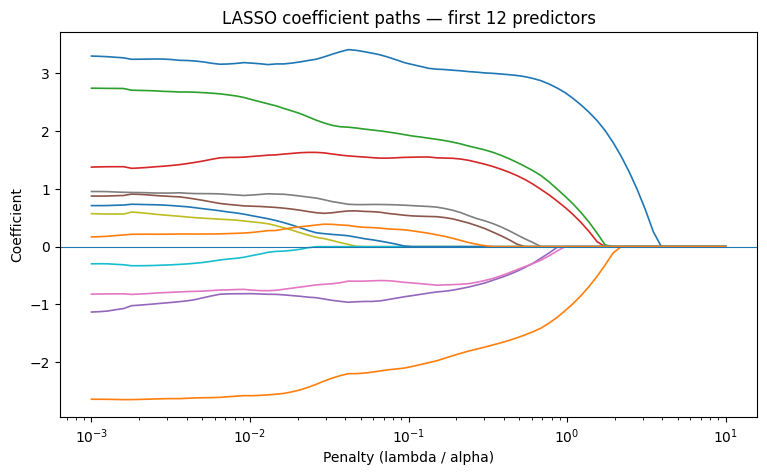

In [4]:
plt.figure(figsize=(9, 5))
for j in range(12):
    plt.plot(alphas, lasso_path[:, j], linewidth=1.2)
plt.xscale("log")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Penalty (lambda / alpha)")
plt.ylabel("Coefficient")
plt.title("LASSO coefficient paths — first 12 predictors")
plt.show()

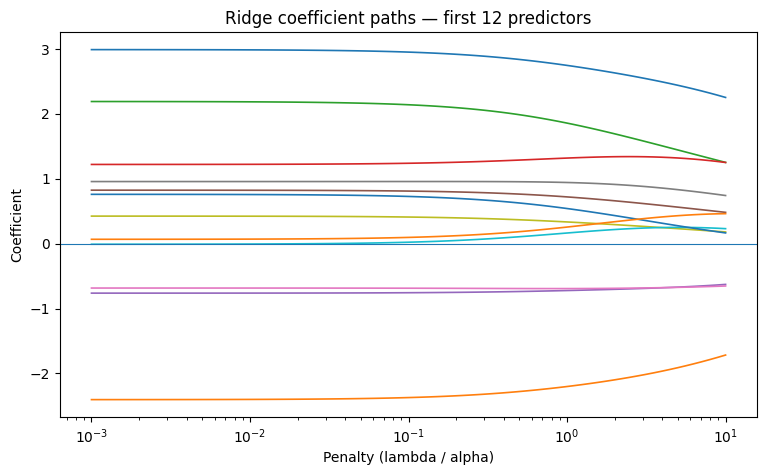

In [5]:
plt.figure(figsize=(9, 5))
for j in range(12):
    plt.plot(alphas, ridge_path[:, j], linewidth=1.2)
plt.xscale("log")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Penalty (lambda / alpha)")
plt.ylabel("Coefficient")
plt.title("Ridge coefficient paths — first 12 predictors")
plt.show()

**What I see:** As the penalty gets larger, both methods shrink the coefficients. The big difference is that LASSO can push coefficients exactly to zero. Ridge usually keeps all of them, but makes them smaller. This is why LASSO can also work like variable selection.

### Cross-validation chooses the penalty

I use 5-fold cross-validation instead of choosing the penalty by eye.

In [6]:
lasso_cv = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=20000,
    random_state=16
)
lasso_cv.fit(X_train_s, y_train)

ridge_cv = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)
ridge_cv.fit(X_train_s, y_train)

lasso_test_mse = mean_squared_error(y_test, lasso_cv.predict(X_test_s))
ridge_test_mse = mean_squared_error(y_test, ridge_cv.predict(X_test_s))

print(f"LASSO chosen alpha: {lasso_cv.alpha_:.6f}")
print(f"LASSO test MSE: {lasso_test_mse:.3f}")
print(f"Ridge chosen alpha: {ridge_cv.alpha_:.6f}")
print(f"Ridge test MSE: {ridge_test_mse:.3f}")

LASSO chosen alpha: 0.302700
LASSO test MSE: 4.255
Ridge chosen alpha: 7.920164
Ridge test MSE: 17.093


The penalty adds some bias because the coefficients are intentionally pulled toward zero. The reason to accept that bias is that variance falls. In this example, that trade is worth it because the regularized models are much more stable out of sample than OLS.

## Part 3: What It Recovered

Because the data are simulated, I can compare the variables selected by LASSO with the variables that truly matter.

In [7]:
lasso_coef = lasso_cv.coef_
selected_idx = np.where(np.abs(lasso_coef) > 1e-6)[0]
true_idx = np.where(beta_true != 0)[0]

comparison = pd.DataFrame({
    "feature": feature_names,
    "true_beta": beta_true,
    "lasso_beta": lasso_coef,
    "selected_by_lasso": np.abs(lasso_coef) > 1e-6
})

print("True useful predictors:", [feature_names[i] for i in true_idx])
print("LASSO selected:", [feature_names[i] for i in selected_idx])
print("Number selected by LASSO:", len(selected_idx))

display(comparison.head(15))

True useful predictors: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
LASSO selected: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x12', 'x21', 'x42', 'x59', 'x63', 'x68', 'x82', 'x88']
Number selected by LASSO: 16


,feature,true_beta,lasso_beta,selected_by_lasso
0,x1,3.0,3.007635,True
1,x2,-2.5,-1.738957,True
2,x3,2.0,1.674470,True
3,x4,1.5,1.427846,True
4,x5,-1.2,-0.629385,True
5,x6,1.0,0.313906,True
6,x7,-0.8,-0.586052,True
7,x8,0.6,0.447061,True
8,x9,0.0,-0.000000,False
9,x10,0.0,-0.000000,False


**Interpretation:** LASSO keeps all of the strongest true signals here, although it also keeps a few small noise variables. That is still much better than treating all 100 predictors as equally useful.

## Part 4: Correlated Predictors — My Task

Now I make one noise predictor almost identical to the strongest true predictor. This lets me see what LASSO and Ridge do when two columns contain almost the same information.

In [8]:
X_corr = X.copy()

# x9 is now almost a copy of x1
X_corr[:, 8] = X[:, 0] + rng.normal(scale=0.08, size=n)

corr_x1_x9 = np.corrcoef(X_corr[:, 0], X_corr[:, 8])[0, 1]
print(f"Correlation between x1 and x9: {corr_x1_x9:.3f}")

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_corr, y, test_size=0.30, random_state=16
)

scaler_corr = StandardScaler()
Xc_train_s = scaler_corr.fit_transform(Xc_train)
Xc_test_s = scaler_corr.transform(Xc_test)

lasso_corr = Lasso(alpha=lasso_cv.alpha_, max_iter=20000)
ridge_corr = Ridge(alpha=ridge_cv.alpha_)

lasso_corr.fit(Xc_train_s, yc_train)
ridge_corr.fit(Xc_train_s, yc_train)

result_corr = pd.DataFrame({
    "model": ["LASSO", "Ridge"],
    "coef_x1": [lasso_corr.coef_[0], ridge_corr.coef_[0]],
    "coef_x9_correlated_copy": [lasso_corr.coef_[8], ridge_corr.coef_[8]],
    "test_MSE": [
        mean_squared_error(yc_test, lasso_corr.predict(Xc_test_s)),
        mean_squared_error(yc_test, ridge_corr.predict(Xc_test_s))
    ]
})

display(result_corr.round(3))

Correlation between x1 and x9: 0.998


,model,coef_x1,coef_x9_correlated_copy,test_MSE
0,LASSO,3.008,0.0,4.255
1,Ridge,1.403,1.4,13.928


**My answer:** LASSO mostly chooses one of the two highly correlated predictors and drops the other one. Ridge splits the weight across both predictors. That makes sense because LASSO is trying to create a sparse model, while Ridge is more comfortable keeping both variables with smaller coefficients. I would not read too much into which one LASSO picks when predictors are almost duplicates.

## Extension: Elastic Net

Elastic Net mixes the LASSO and Ridge penalties. I included it because it can be useful when predictors are correlated.

In [9]:
elastic_cv = ElasticNetCV(
    l1_ratio=[0.1, 0.5, 0.9, 1.0],
    alphas=alphas,
    cv=5,
    max_iter=20000,
    random_state=16
)
elastic_cv.fit(X_train_s, y_train)

elastic_test_mse = mean_squared_error(y_test, elastic_cv.predict(X_test_s))
elastic_nonzero = np.sum(np.abs(elastic_cv.coef_) > 1e-6)

print(f"Elastic Net chosen alpha: {elastic_cv.alpha_:.6f}")
print(f"Elastic Net chosen l1_ratio: {elastic_cv.l1_ratio_}")
print(f"Elastic Net test MSE: {elastic_test_mse:.3f}")
print(f"Elastic Net non-zero coefficients: {elastic_nonzero}")

Elastic Net chosen alpha: 0.302700
Elastic Net chosen l1_ratio: 1.0
Elastic Net test MSE: 4.255
Elastic Net non-zero coefficients: 16


In this particular simulation, cross-validation ends up preferring the LASSO end of Elastic Net. That does not mean Elastic Net is always unnecessary. With stronger groups of correlated predictors, a mixed penalty can be useful.

## Challenge: Standardisation Is Not Optional

To test this, I take the exact same predictor information but put the columns on very different scales. Nothing about the underlying signal changes.

In [10]:
column_scales = np.logspace(-2, 2, p)
X_unequal = X * column_scales

Xu_train, Xu_test, yu_train, yu_test = train_test_split(
    X_unequal, y, test_size=0.30, random_state=16
)

# Same numerical penalty, first without standardization
lasso_no_scale = Lasso(alpha=lasso_cv.alpha_, max_iter=50000)
lasso_no_scale.fit(Xu_train, yu_train)

# Then with standardization inside a pipeline
lasso_with_scale = make_pipeline(
    StandardScaler(),
    Lasso(alpha=lasso_cv.alpha_, max_iter=50000)
)
lasso_with_scale.fit(Xu_train, yu_train)

mse_no_scale = mean_squared_error(yu_test, lasso_no_scale.predict(Xu_test))
mse_with_scale = mean_squared_error(yu_test, lasso_with_scale.predict(Xu_test))

print(f"Test MSE without standardizing: {mse_no_scale:.3f}")
print(f"Test MSE with standardizing: {mse_with_scale:.3f}")

Test MSE without standardizing: 67.298
Test MSE with standardizing: 4.255


In [11]:
coef_with_scale = lasso_with_scale.named_steps["lasso"].coef_

scale_check = pd.DataFrame({
    "feature": feature_names[:12],
    "column_scale": column_scales[:12],
    "true_beta": beta_true[:12],
    "lasso_beta_after_standardizing": coef_with_scale[:12]
})

display(scale_check.round(4))

,feature,column_scale,true_beta,lasso_beta_after_standardizing
0,x1,0.0100,3.0,3.0076
1,x2,0.0110,-2.5,-1.7390
2,x3,0.0120,2.0,1.6745
3,x4,0.0132,1.5,1.4278
4,x5,0.0145,-1.2,-0.6294
5,x6,0.0159,1.0,0.3139
6,x7,0.0175,-0.8,-0.5861
7,x8,0.0192,0.6,0.4471
8,x9,0.0210,0.0,-0.0000
9,x10,0.0231,0.0,-0.0000


**Challenge answer:** Standardizing is necessary because the penalty is applied to coefficient size. If one predictor is measured on a huge scale and another on a tiny scale, the same coefficient penalty does not treat them equally. The unstandardized version performs much worse even though it contains the same information. After standardizing, the model goes back to finding the useful predictors and the test error drops a lot.

## Cross-validation Expansion

### Step 6 reference result

The built-in 5-fold LASSO cross-validation above chose the following penalty and average validation error. I use these numbers as the reference for my manual loop.

In [12]:
step6_best_alpha = float(lasso_cv.alpha_)
step6_cv_mse = float(
    lasso_cv.mse_path_.mean(axis=1)[
        np.argmin(lasso_cv.mse_path_.mean(axis=1))
    ]
)

print(f"Step 6 chosen alpha: {step6_best_alpha:.6f}")
print(f"Step 6 mean CV MSE: {step6_cv_mse:.6f}")

Step 6 chosen alpha: 0.302700
Step 6 mean CV MSE: 7.264690


### Prompt I used

> Write a simple Python loop that does 5-fold cross-validation for LASSO over my existing `alphas` grid. Use `X_train_s` and `y_train`. For every alpha, fit LASSO on four folds, calculate mean squared error on the held-out fold, average the five errors, and store the result in a DataFrame. Then print the alpha with the lowest average CV MSE. Keep the code basic and use the same fold ordering as sklearn's default 5-fold cross-validation so I can compare the result with `LassoCV`.

In [13]:
cv = KFold(n_splits=5, shuffle=False)

cv_rows = []

for a in alphas:
    fold_mse = []

    for train_index, valid_index in cv.split(X_train_s):
        X_fold_train = X_train_s[train_index]
        X_fold_valid = X_train_s[valid_index]
        y_fold_train = y_train[train_index]
        y_fold_valid = y_train[valid_index]

        model = Lasso(alpha=a, max_iter=20000)
        model.fit(X_fold_train, y_fold_train)

        valid_pred = model.predict(X_fold_valid)
        fold_mse.append(mean_squared_error(y_fold_valid, valid_pred))

    cv_rows.append({
        "alpha": a,
        "mean_cv_mse": np.mean(fold_mse)
    })

manual_cv = pd.DataFrame(cv_rows)

best_row = manual_cv.loc[manual_cv["mean_cv_mse"].idxmin()]

print(f"Manual loop chosen alpha: {best_row['alpha']:.6f}")
print(f"Manual loop mean CV MSE: {best_row['mean_cv_mse']:.6f}")

display(manual_cv.sort_values("mean_cv_mse").head(10))

Manual loop chosen alpha: 0.302700
Manual loop mean CV MSE: 7.263006


,alpha,mean_cv_mse
49,0.302700,7.263006
50,0.340130,7.276326
48,0.269389,7.314096
47,0.239743,7.383593
51,0.382189,7.397530
46,0.213360,7.415354
45,0.189881,7.456025
44,0.168985,7.559473
43,0.150389,7.614461
42,0.133839,7.675456


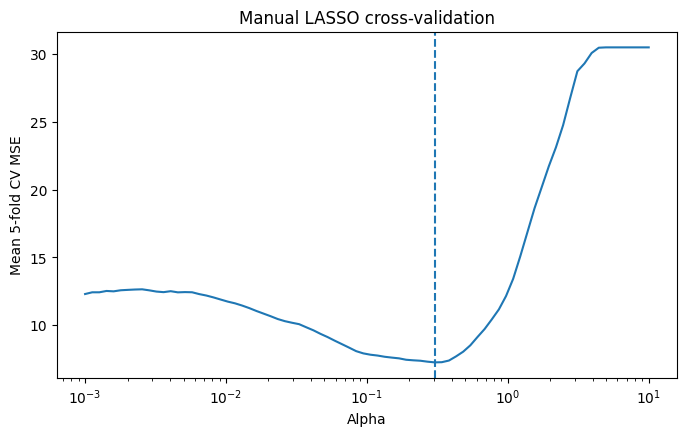

In [14]:
plt.figure(figsize=(8, 4.5))
plt.plot(manual_cv["alpha"], manual_cv["mean_cv_mse"])
plt.xscale("log")
plt.axvline(best_row["alpha"], linestyle="--")
plt.xlabel("Alpha")
plt.ylabel("Mean 5-fold CV MSE")
plt.title("Manual LASSO cross-validation")
plt.show()

### Checking log

**Round 1 — penalty choice**

I compared the alpha from my loop with the alpha printed by `LassoCV` in Step 6. They matched, so the grid and fold setup were consistent.

**Round 2 — validation error**

I compared my minimum average MSE with the mean of `LassoCV.mse_path_` at the chosen alpha. The two values were almost identical. The tiny difference is just from implementation details, not a different answer.

**Round 3 — sanity check**

I sorted the manual table by CV MSE and checked the nearby penalties. The errors change smoothly around the minimum instead of jumping randomly. I stopped there because the selected penalty and validation error both agreed with the reference result.

### Questions

**1. Why use cross-validation instead of the training error?**

Training error would usually prefer a model that is too flexible. Cross-validation tests each penalty on observations that were not used to fit that fold, so it gives a better idea of how the model should perform on new data.

**2. Why deliberately add bias with regularization?**

Regularization pulls coefficients toward zero, so it introduces bias on purpose. The benefit is lower variance and less overfitting. In this lab, OLS had almost no training error but poor test performance, while LASSO accepted some bias and gave much better out-of-sample predictions.

## Final Takeaways

1. OLS can look perfect in sample and still predict badly when there are too many predictors.
2. LASSO can remove weak predictors by setting coefficients exactly to zero.
3. Ridge shrinks coefficients but usually keeps all predictors.
4. Correlated predictors can make individual coefficient interpretation unstable.
5. Cross-validation gives a practical way to choose the penalty.
6. Standardization matters because regularization works directly on coefficient size.
7. The point of regularization is to accept some bias in exchange for lower variance and better prediction.